# Hotel Booking Revenue Analysis

I am using the hotel booking file to understand which bookings make more revenue and which bookings may need attention. In this study, a booking is **At Risk** if `Total_Revenue_INR` is below ₹10,000.

## 1. Reading the file

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('../data/raw/hotel_data.csv')
print(df.shape)
df.head()

(255, 12)


,Booking_ID,Check_In_Date,City,Room_Type,Booking_Channel,Guest_Type,Nights,Guests,Lead_Time_Days,Room_Rate_INR,Guest_Age,Total_Revenue_INR
0,H1247,2026-04-23,Mumbai,Suite,Website,Leisure,4,3.0,22.0,6900,32.0,21000
1,H1113,2025-06-17,Delhi,Standard,Walk_In,Business,2,3.0,44.0,3350,37.0,1500
2,H1046,2025-04-10,Jaipur,Suite,Website,Family,9,4.0,44.0,7400,41.0,37520
3,H1176,2026-07-06,Jaipur,Deluxe,Website,Business,3,1.0,27.0,3250,30.0,12530
4,H1089,2025-10-06,Jaipur,Standard,Website,Leisure,4,1.0,3.0,2650,56.0,19290


The file has 255 rows and 12 columns. I checked the last few rows, column types and basic counts before cleaning.

In [2]:
df.tail()
print(df.dtypes)
print('\nMissing values:')
print(df.isna().sum())
print('\nDuplicate rows:', df.duplicated().sum())

Booking_ID               str
Check_In_Date            str
City                     str
Room_Type                str
Booking_Channel          str
Guest_Type               str
Nights                 int64
Guests               float64
Lead_Time_Days       float64
Room_Rate_INR          int64
Guest_Age            float64
Total_Revenue_INR      int64
dtype: object

Missing values:
Booking_ID           0
Check_In_Date        0
City                 0
Room_Type            0
Booking_Channel      5
Guest_Type           0
Nights               0
Guests               5
Lead_Time_Days       5
Room_Rate_INR        0
Guest_Age            5
Total_Revenue_INR    0
dtype: int64

Duplicate rows: 5


## 2. Problems I found

- 5 duplicate rows
- City names were written in different ways
- 5 missing booking-channel values
- 5 missing guest counts
- 5 missing lead-time values
- 5 missing ages
- 2 impossible ages: -27 and 212

## 3. Cleaning

I removed repeated rows and made city names consistent. Blank values were filled with the most common or middle value. For the two strange ages, I used the median of the valid ages instead of deleting the whole bookings.

In [3]:
df['City'] = df['City'].str.strip().str.lower()
df['City'] = df['City'].replace({
    'delhi':'Delhi', 'mumbai':'Mumbai', 'bengaluru':'Bengaluru',
    'jaipur':'Jaipur', 'goa':'Goa'
})
df = df.drop_duplicates()
df['Booking_Channel'] = df['Booking_Channel'].fillna(df['Booking_Channel'].mode()[0])
for c in ['Guests', 'Lead_Time_Days', 'Guest_Age']:
    df[c] = pd.to_numeric(df[c], errors='coerce')
    df[c] = df[c].fillna(df[c].median())
valid_median = df[df['Guest_Age'].between(18,80)]['Guest_Age'].median()
df.loc[~df['Guest_Age'].between(18,80), 'Guest_Age'] = valid_median
df['Check_In_Date'] = pd.to_datetime(df['Check_In_Date'])
print('Cleaned shape:', df.shape)
print('Missing values:', df.isna().sum().sum())
print('Duplicate rows:', df.duplicated().sum())

Cleaned shape: (250, 12)
Missing values: 0
Duplicate rows: 0


## 4. Extra columns

I also calculated expected revenue, revenue per guest, a broad revenue status and a short/medium/long stay label.

In [4]:
df['Expected_Revenue_INR'] = df['Nights'] * df['Room_Rate_INR']
df['Revenue_per_Guest_INR'] = df['Total_Revenue_INR'] / df['Guests']
df['Revenue_Status'] = 'Average'
df.loc[df['Total_Revenue_INR'] < 10000, 'Revenue_Status'] = 'At Risk'
df.loc[df['Total_Revenue_INR'] >= 20000, 'Revenue_Status'] = 'High Value'
df['Stay_Length_Band'] = pd.cut(df['Nights'], [0,2,5,10], labels=['Short','Medium','Long'])
df['At_Risk'] = df['Total_Revenue_INR'] < 10000
df.to_csv('../data/processed/hotel_data_clean.csv', index=False)
df.head()

,Booking_ID,Check_In_Date,City,Room_Type,Booking_Channel,Guest_Type,Nights,Guests,Lead_Time_Days,Room_Rate_INR,Guest_Age,Total_Revenue_INR,Expected_Revenue_INR,Revenue_per_Guest_INR,Revenue_Status,Stay_Length_Band,At_Risk
0,H1247,2026-04-23,Mumbai,Suite,Website,Leisure,4,3.0,22.0,6900,32.0,21000,27600,7000.0,High Value,Medium,False
1,H1113,2025-06-17,Delhi,Standard,Walk_In,Business,2,3.0,44.0,3350,37.0,1500,6700,500.0,At Risk,Short,True
2,H1046,2025-04-10,Jaipur,Suite,Website,Family,9,4.0,44.0,7400,41.0,37520,66600,9380.0,High Value,Long,False
3,H1176,2026-07-06,Jaipur,Deluxe,Website,Business,3,1.0,27.0,3250,30.0,12530,9750,12530.0,Average,Medium,False
4,H1089,2025-10-06,Jaipur,Standard,Website,Leisure,4,1.0,3.0,2650,56.0,19290,10600,19290.0,Average,Medium,False


## 5. Question 1: What does revenue look like?

In [5]:
revenue = df['Total_Revenue_INR']
print('Average:', round(revenue.mean(), 2))
print('Median:', revenue.median())
print('Lowest:', revenue.min())
print('Highest:', revenue.max())

Average: 16651.24
Median: 16165.0
Lowest: 1500
Highest: 45980


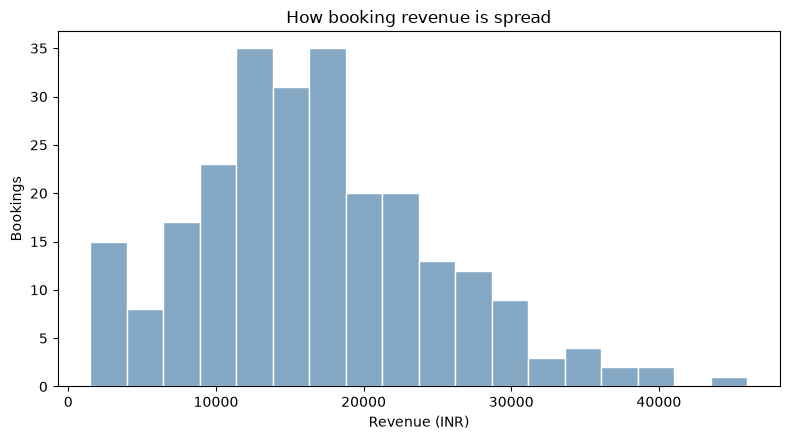

In [6]:
plt.figure(figsize=(8,4.5))
plt.hist(revenue, bins=18, color='#84a8c4', edgecolor='white')
plt.title('How booking revenue is spread')
plt.xlabel('Revenue (INR)')
plt.ylabel('Bookings')
plt.tight_layout()
plt.savefig('../charts/revenue_distribution.png', dpi=150)
plt.show()

The average is ₹16,651.24 and the middle value is ₹16,165. The chart is uneven and slightly stretched towards high revenue.

## 6. Question 2: Do nights or room rate affect revenue?

In [7]:
print('Correlations:')
print(df[['Nights','Room_Rate_INR','Guests','Lead_Time_Days','Guest_Age','Total_Revenue_INR']].corr()['Total_Revenue_INR'])

Correlations:
Nights               0.558131
Room_Rate_INR        0.604084
Guests              -0.020866
Lead_Time_Days       0.029306
Guest_Age            0.022462
Total_Revenue_INR    1.000000
Name: Total_Revenue_INR, dtype: float64


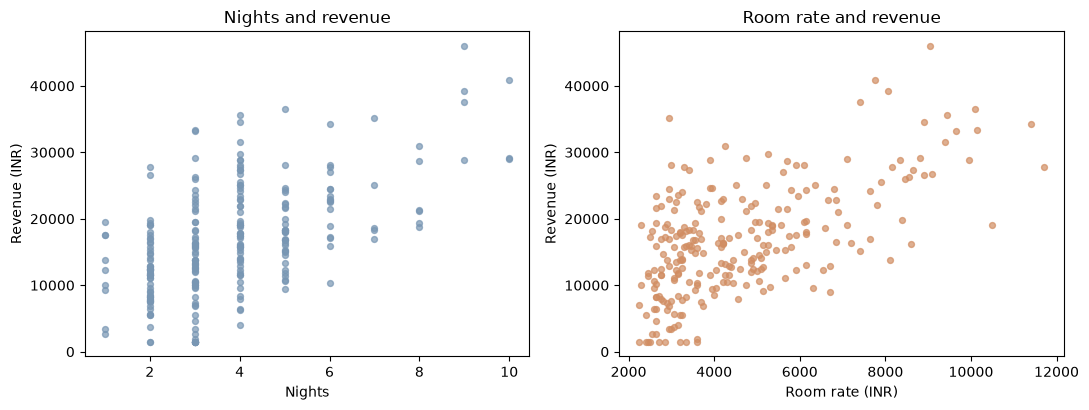

In [8]:
fig, ax = plt.subplots(1,2, figsize=(11,4.2))
ax[0].scatter(df['Nights'], revenue, s=18, color='#7896b3', alpha=.7)
ax[0].set(title='Nights and revenue', xlabel='Nights', ylabel='Revenue (INR)')
ax[1].scatter(df['Room_Rate_INR'], revenue, s=18, color='#d18d62', alpha=.7)
ax[1].set(title='Room rate and revenue', xlabel='Room rate (INR)', ylabel='Revenue (INR)')
plt.tight_layout()
plt.savefig('../charts/nights_and_room_rate.png', dpi=150)
plt.show()

Nights and room rate have the strongest positive connections in this table. Guest count, lead time and age do not show much of a pattern.

## 7. Question 3: Which groups have higher revenue?

In [9]:
for col in ['City','Room_Type','Booking_Channel','Guest_Type']:
    print('\nAverage by', col)
    print(df.groupby(col)['Total_Revenue_INR'].mean().round(2).sort_values(ascending=False))


Average by City
City
Goa          20760.91
Delhi        17173.60
Mumbai       17062.58
Bengaluru    15943.75
Jaipur       13834.19
Name: Total_Revenue_INR, dtype: float64

Average by Room_Type
Room_Type
Suite       27320.00
Deluxe      17496.18
Standard    12977.04
Name: Total_Revenue_INR, dtype: float64

Average by Booking_Channel
Booking_Channel
Travel_Agent    17813.84
Walk_In         17431.95
Website         16910.62
Mobile_App      14144.18
Name: Total_Revenue_INR, dtype: float64

Average by Guest_Type
Guest_Type
Leisure     16961.42
Business    16843.05
Family      15728.00
Name: Total_Revenue_INR, dtype: float64


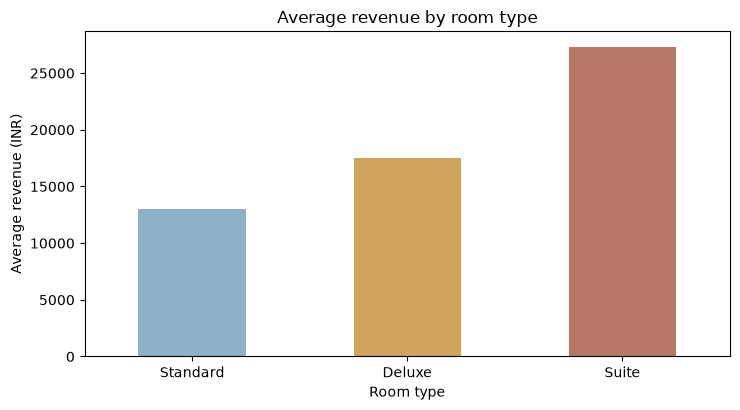

In [10]:
room_avg = df.groupby('Room_Type')['Total_Revenue_INR'].mean().sort_values()
room_avg.plot(kind='bar', color=['#8db1c7','#d1a35c','#b87867'], figsize=(7.5,4.2))
plt.title('Average revenue by room type')
plt.xlabel('Room type')
plt.ylabel('Average revenue (INR)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../charts/revenue_by_room_type.png', dpi=150)
plt.show()

Suites have the highest average revenue at ₹27,320. Standard rooms are lowest at ₹12,977. Among the categories checked, room type has the largest spread.

## 8. Question 4: Which bookings need attention?

In [11]:
at_risk = df[df['At_Risk']].copy()
print('At-risk count:', len(at_risk))
print('Percentage:', round(len(at_risk)/len(df)*100, 1), '%')
print('\nBy city:\n', at_risk['City'].value_counts())
print('\nBy room type:\n', at_risk['Room_Type'].value_counts())
print('\nBy channel:\n', at_risk['Booking_Channel'].value_counts())

At-risk count: 50
Percentage: 20.0 %

By city:
 City
Jaipur       14
Mumbai       13
Delhi        12
Bengaluru     9
Goa           2
Name: count, dtype: int64

By room type:
 Room_Type
Standard    43
Deluxe       7
Name: count, dtype: int64

By channel:
 Booking_Channel
Mobile_App      19
Website         16
Travel_Agent     8
Walk_In          7
Name: count, dtype: int64


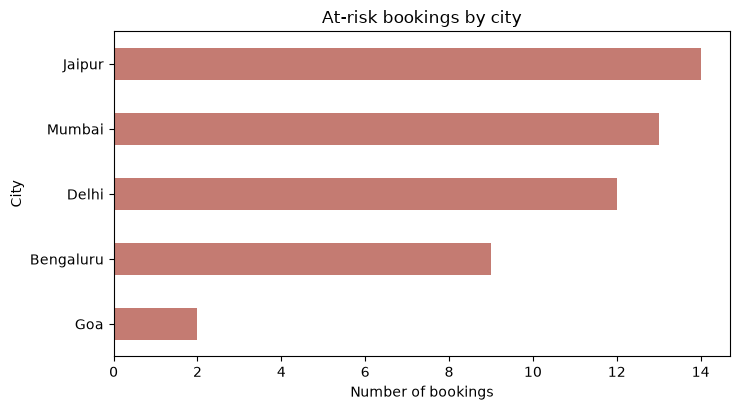

,Booking_ID,City,Room_Type,Booking_Channel,Nights,Room_Rate_INR,Total_Revenue_INR
1,H1113,Delhi,Standard,Walk_In,2,3350,1500
6,H1065,Jaipur,Standard,Mobile_App,3,2550,2710
7,H1181,Delhi,Standard,Travel_Agent,2,2800,7650
14,H1240,Mumbai,Standard,Website,5,3950,9450
17,H1059,Bengaluru,Standard,Mobile_App,2,3000,7630
19,H1148,Bengaluru,Deluxe,Website,2,4550,7890
24,H1086,Jaipur,Standard,Website,3,2700,1500
25,H1144,Mumbai,Deluxe,Travel_Agent,3,5300,9660
28,H1115,Goa,Deluxe,Website,2,5150,9070
33,H1221,Jaipur,Standard,Mobile_App,3,2900,7350


In [12]:
counts = at_risk['City'].value_counts().sort_values()
counts.plot(kind='barh', color='#c47b72', figsize=(7.5,4.2))
plt.title('At-risk bookings by city')
plt.xlabel('Number of bookings')
plt.ylabel('City')
plt.tight_layout()
plt.savefig('../charts/at_risk_by_city.png', dpi=150)
plt.show()

at_risk[['Booking_ID','City','Room_Type','Booking_Channel','Nights','Room_Rate_INR','Total_Revenue_INR']].head(10)

### Short conclusion

There are 50 at-risk bookings, which is 20% of the cleaned file. Jaipur has the most, followed by the pattern in the table. Standard rooms and Mobile app bookings appear particularly often in this low-revenue group.

The data is synthetic and small, so these are useful patterns to investigate rather than proof that one factor caused higher revenue.